In [1]:
# Imports
import sys
from pathlib import Path

sys.path.insert(0, str(Path("../..").resolve()))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display, clear_output
import ipywidgets as widgets

from src.clustering.helpers import HelperFunctions
helper = HelperFunctions()

In [2]:
# Shared paths & thresholds — from src/config.py
from src.config import (
    ASSETS_PATH, ASSET_DAILY_PATH,
    MIN_VOLUME_24H_USD,
    DATE_COL as DATE_COLUMN,
    VOLUME_COL as VOLUME_COLUMN,
)

# Notebook-specific configuration
LOOKBACK_DAYS = 7

# Basket thresholds — tuned per dataset, stay here. Ascending list of N-1 upper
# bounds for an N-basket split (see src.clustering.helpers.HelperFunctions.assign_volume_basket);
# add/remove entries to change how many baskets there are.
BASKET_UPPER_BOUNDS = [100_000_000, 250_000_000, 1_000_000_000]

In [3]:
# Core Helpers
def load_table(table_path: Path) -> pd.DataFrame:
    if not table_path.exists():
        raise FileNotFoundError(f"No data stored at {table_path}")

    return pd.read_parquet(table_path)


def get_asset_id_column(df: pd.DataFrame) -> str:
    possible_id_columns = ["asset_id", "coingecko_id", "id"]

    for column in possible_id_columns:
        if column in df.columns:
            return column

    raise KeyError(
        "No asset identifier column found. Expected one of: "
        f"{possible_id_columns}"
    )


def add_asset_metadata(
    df: pd.DataFrame,
    assets_df: pd.DataFrame,
    *,
    id_column: str,
) -> pd.DataFrame:
    metadata_columns = [id_column, "symbol", "name"]

    missing_columns = [
        column for column in metadata_columns
        if column not in assets_df.columns
    ]

    if missing_columns:
        raise KeyError(
            "Missing metadata columns in assets_df: "
            f"{missing_columns}"
        )

    asset_metadata_df = (
        assets_df[metadata_columns]
        .drop_duplicates(subset=[id_column])
        .copy()
    )

    return df.merge(
        asset_metadata_df,
        on=id_column,
        how="left",
    )


def nice_volume_threshold(value: float) -> int | None:
    if pd.isna(value):
        return None

    magnitude = 10 ** np.floor(np.log10(value))
    normalized = value / magnitude

    if normalized <= 1:
        nice = 1
    elif normalized <= 2.5:
        nice = 2.5
    elif normalized <= 5:
        nice = 5
    else:
        nice = 10

    return int(nice * magnitude)


def suggest_fixed_thresholds(
    rolling_volume_df: pd.DataFrame,
    *,
    min_volume_24h_usd: float,
) -> dict:
    eligible_df = rolling_volume_df.loc[
        rolling_volume_df["rolling_median_volume_24h_usd"] >= min_volume_24h_usd
    ].copy()

    raw_thresholds = eligible_df["rolling_median_volume_24h_usd"].quantile(
        [0.25, 0.50, 0.75]
    )

    return {
        "basket_4_upper": nice_volume_threshold(raw_thresholds.loc[0.25]),
        "basket_3_upper": nice_volume_threshold(raw_thresholds.loc[0.50]),
        "basket_2_upper": nice_volume_threshold(raw_thresholds.loc[0.75]),
    }

In [4]:
# Load Data
assets_df = load_table(ASSETS_PATH)
asset_daily_df = load_table(ASSET_DAILY_PATH)

asset_daily_df[DATE_COLUMN] = pd.to_datetime(asset_daily_df[DATE_COLUMN])

id_column = get_asset_id_column(asset_daily_df)

rolling_volume_df = helper.compute_rolling_volume_table(
    asset_daily_df,
    id_column=id_column,
    date_column=DATE_COLUMN,
    volume_column=VOLUME_COLUMN,
    lookback_days=LOOKBACK_DAYS,
)

available_dates = sorted(rolling_volume_df[DATE_COLUMN].dropna().unique())
available_dates = [pd.Timestamp(date) for date in available_dates]

print(f"asset_daily_df: {asset_daily_df.shape}")
print(f"assets_df: {assets_df.shape}")
print(f"Asset ID column: {id_column}")
print(f"Dates: {available_dates[0].date()} to {available_dates[-1].date()}")

asset_daily_df: (29523, 5)
assets_df: (57, 9)
Asset ID column: asset_id
Dates: 2024-07-23 to 2026-07-23


In [5]:
# Suggest Fixed Thresholds
threshold_suggestions = suggest_fixed_thresholds(
    rolling_volume_df,
    min_volume_24h_usd=MIN_VOLUME_24H_USD,
)

print("Suggested thresholds based on 7-day median volume quantiles:")
print(f"Basket 4 upper: ${threshold_suggestions['basket_4_upper']:,.0f}")
print(f"Basket 3 upper: ${threshold_suggestions['basket_3_upper']:,.0f}")
print(f"Basket 2 upper: ${threshold_suggestions['basket_2_upper']:,.0f}")

print("\nCurrent fixed basket definitions:")
for line in helper.describe_volume_baskets(BASKET_UPPER_BOUNDS, MIN_VOLUME_24H_USD):
    print(line)

Suggested thresholds based on 7-day median volume quantiles:
Basket 4 upper: $250,000,000
Basket 3 upper: $500,000,000
Basket 2 upper: $1,000,000,000

Current fixed basket definitions:
Basket 4: $50,000,000 <= volume < $100,000,000
Basket 3: $100,000,000 <= volume < $250,000,000
Basket 2: $250,000,000 <= volume < $1,000,000,000
Basket 1: volume >= $1,000,000,000


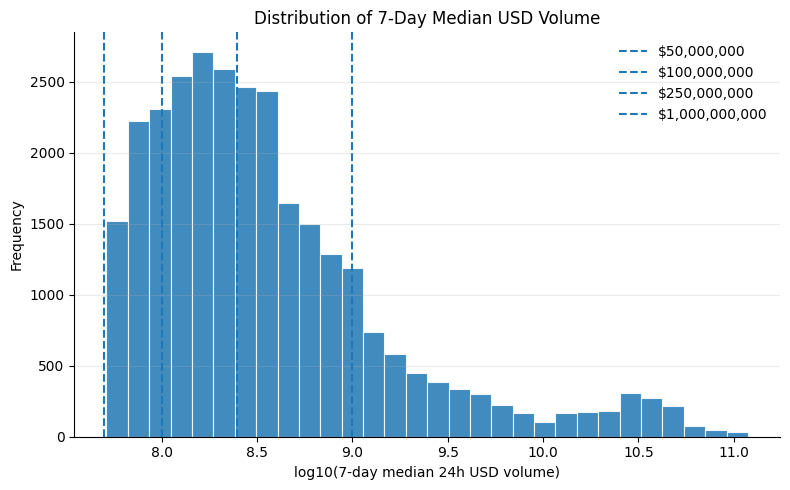

In [6]:
# Plot Volume Distribution With Fixed Thresholds
eligible_volume_df = rolling_volume_df.loc[
    rolling_volume_df["rolling_median_volume_24h_usd"] >= MIN_VOLUME_24H_USD
].copy()

fig, ax = plt.subplots(figsize=(8, 5))

ax.hist(
    eligible_volume_df["log_rolling_median_volume_24h_usd"].dropna(),
    bins=30,
    edgecolor="white",
    linewidth=0.8,
    alpha=0.85,
)

for threshold in [MIN_VOLUME_24H_USD] + list(BASKET_UPPER_BOUNDS):
    ax.axvline(
        np.log10(threshold),
        linestyle="--",
        linewidth=1.5,
        label=f"${threshold:,.0f}",
    )

ax.set_title("Distribution of 7-Day Median USD Volume")
ax.set_xlabel("log10(7-day median 24h USD volume)")
ax.set_ylabel("Frequency")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.grid(axis="y", alpha=0.25)
ax.legend(frameon=False)

fig.tight_layout()
plt.show()

In [7]:
# Basket Analysis Helpers
def summarize_basket_counts(basket_df: pd.DataFrame) -> pd.DataFrame:
    return (
        basket_df
        .groupby("basket", observed=True)
        .size()
        .rename("asset_count")
        .reset_index()
        .sort_values("basket")
    )


def summarize_basket_volume(
    basket_df: pd.DataFrame,
    *,
    id_column: str,
) -> pd.DataFrame:
    return (
        basket_df
        .groupby("basket", observed=True)
        .agg(
            asset_count=(id_column, "count"),
            min_volume=("rolling_median_volume_24h_usd", "min"),
            median_volume=("rolling_median_volume_24h_usd", "median"),
            mean_volume=("rolling_median_volume_24h_usd", "mean"),
            max_volume=("rolling_median_volume_24h_usd", "max"),
        )
        .reset_index()
        .sort_values("basket")
    )


def compute_max_basket_count(
    rolling_volume_df: pd.DataFrame,
    *,
    date_column: str,
    basket_upper_bounds: list[float],
) -> int:
    # Scans every date's basket sizes so the bar chart's y-axis can stay fixed,
    # instead of autoscaling to whichever day happens to be selected.
    basket_series = rolling_volume_df["rolling_median_volume_24h_usd"].apply(
        lambda volume: helper.assign_volume_basket(
            volume,
            basket_upper_bounds=basket_upper_bounds,
        )
    )

    daily_basket_counts = (
        rolling_volume_df.loc[basket_series.notna(), [date_column]]
        .assign(basket=basket_series.dropna())
        .groupby([date_column, "basket"], observed=True)
        .size()
    )

    return int(daily_basket_counts.max())


def summarize_changes(
    comparison_df: pd.DataFrame,
    left_df: pd.DataFrame,
) -> pd.DataFrame:
    current_changes = (
        comparison_df["basket_change"]
        .value_counts()
        .rename_axis("change_type")
        .reset_index(name="asset_count")
    )

    if left_df.empty:
        return current_changes

    left_count = pd.DataFrame(
        {
            "change_type": ["left universe"],
            "asset_count": [len(left_df)],
        }
    )

    return pd.concat(
        [current_changes, left_count],
        ignore_index=True,
    )


def get_changed_assets(
    comparison_df: pd.DataFrame,
    left_df: pd.DataFrame,
    *,
    assets_df: pd.DataFrame,
    id_column: str,
) -> pd.DataFrame:
    output_columns = [
        id_column,
        "symbol",
        "name",
        "previous_basket",
        "basket",
        "rolling_median_volume_24h_usd",
        "basket_change",
    ]

    entered_or_switched_df = (
        comparison_df
        .loc[
            comparison_df["basket_change"].isin(
                ["entered universe", "switched basket"]
            ),
            [
                id_column,
                "previous_basket",
                "basket",
                "rolling_median_volume_24h_usd",
                "basket_change",
            ],
        ]
        .copy()
    )

    if not left_df.empty:
        left_assets_df = left_df.copy()
        left_assets_df["basket"] = pd.NA

        entered_or_switched_df = pd.concat(
            [
                entered_or_switched_df,
                left_assets_df[
                    [
                        id_column,
                        "previous_basket",
                        "basket",
                        "rolling_median_volume_24h_usd",
                        "basket_change",
                    ]
                ],
            ],
            ignore_index=True,
        )

    entered_or_switched_df = add_asset_metadata(
        entered_or_switched_df,
        assets_df,
        id_column=id_column,
    )

    return entered_or_switched_df[output_columns]


def get_current_basket_members(
    comparison_df: pd.DataFrame,
    assets_df: pd.DataFrame,
    *,
    id_column: str,
) -> pd.DataFrame:
    basket_members_df = add_asset_metadata(
        comparison_df,
        assets_df,
        id_column=id_column,
    )

    basket_members_df = basket_members_df.sort_values(
        "rolling_median_volume_24h_usd",
        ascending=False,
    )

    return basket_members_df[
        [
            id_column,
            "symbol",
            "name",
            "basket",
            "previous_basket",
            "rolling_median_volume_24h_usd",
            "basket_change",
        ]
    ]


def plot_basket_counts(
    basket_counts_df: pd.DataFrame,
    selected_date: pd.Timestamp,
    *,
    max_asset_count: int,
):
    fig, ax = plt.subplots(figsize=(7, 4))

    ax.bar(
        basket_counts_df["basket"].astype(str),
        basket_counts_df["asset_count"],
    )

    ax.set_title(f"Basket Sizes on {selected_date.date()}")
    ax.set_xlabel("Basket")
    ax.set_ylabel("Number of assets")
    ax.set_ylim(0, max_asset_count * 1.05)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.grid(axis="y", alpha=0.25)

    fig.tight_layout()
    plt.show()


def plot_basket_volume_boxplot(
    basket_df: pd.DataFrame,
    selected_date: pd.Timestamp,
    *,
    basket_labels: list[str],
):
    data = [
        basket_df.loc[
            basket_df["basket"] == basket,
            "rolling_median_volume_24h_usd",
        ].dropna()
        for basket in basket_labels
    ]

    labels = [
        basket
        for basket, values in zip(basket_labels, data)
        if len(values) > 0
    ]

    data = [values for values in data if len(values) > 0]

    fig, ax = plt.subplots(figsize=(7, 4))

    ax.boxplot(data, labels=labels)

    ax.set_title(f"Volume Distribution by Basket on {selected_date.date()}")
    ax.set_xlabel("Basket")
    ax.set_ylabel("7-day median 24h USD volume")
    ax.set_yscale("log")

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.grid(axis="y", alpha=0.25)

    fig.tight_layout()
    plt.show()


# Basket labels in display order (Basket 1 = highest volume tier), derived from
# however many baskets BASKET_UPPER_BOUNDS currently defines.
BASKET_LABELS = [f"Basket {n}" for n in range(1, len(BASKET_UPPER_BOUNDS) + 2)]

# Fixed y-axis ceiling for the basket-size bar chart, computed once across
# every available date so the scale doesn't jump around as you change days.
MAX_BASKET_COUNT = compute_max_basket_count(
    rolling_volume_df,
    date_column=DATE_COLUMN,
    basket_upper_bounds=BASKET_UPPER_BOUNDS,
)

print(f"Basket labels: {BASKET_LABELS}")
print(f"Fixed y-axis ceiling for basket counts: {MAX_BASKET_COUNT}")

Basket labels: ['Basket 1', 'Basket 2', 'Basket 3', 'Basket 4']
Fixed y-axis ceiling for basket counts: 26


In [8]:
# Basket Comparison
# min=LOOKBACK_DAYS - 1: the rolling median needs LOOKBACK_DAYS observations to stop
# being NaN, so the earliest date index with a valid (non-NaN) rolling median is
# LOOKBACK_DAYS - 1 (0-based) -- LOOKBACK_DAYS itself was one day later than
# necessary. On that first valid day, previous_date's rolling median is still NaN
# (empty previous basket), so every asset correctly shows up as "entered universe".
date_slider = widgets.IntSlider(
    value=len(available_dates) - 1,
    min=LOOKBACK_DAYS - 1,
    max=len(available_dates) - 1,
    step=1,
    description="Day",
    continuous_update=False,
)

previous_button = widgets.Button(
    description="Previous day",
    button_style="",
)

next_button = widgets.Button(
    description="Next day",
    button_style="",
)

output = widgets.Output()


def render_fixed_threshold_baskets(date_index):
    with output:
        clear_output(wait=True)

        selected_date = available_dates[date_index]
        previous_date = available_dates[date_index - 1]

        (
            previous_basket_df,
            current_basket_df,
            comparison_df,
            left_df,
            transition_df,
        ) = helper.build_basket_comparison(
            rolling_volume_df,
            previous_date=previous_date,
            selected_date=selected_date,
            id_column=id_column,
            date_column=DATE_COLUMN,
            basket_upper_bounds=BASKET_UPPER_BOUNDS,
        )

        basket_counts_df = summarize_basket_counts(current_basket_df)

        basket_volume_summary_df = summarize_basket_volume(
            current_basket_df,
            id_column=id_column,
        )

        change_summary_df = summarize_changes(comparison_df, left_df)

        changed_assets_df = get_changed_assets(
            comparison_df,
            left_df,
            assets_df=assets_df,
            id_column=id_column,
        )

        current_basket_members_df = get_current_basket_members(
            comparison_df,
            assets_df,
            id_column=id_column,
        )

        print(f"Selected date: {selected_date.date()}")
        print(f"Compared with: {previous_date.date()}")
        print(f"Lookback: {LOOKBACK_DAYS} days")
        print(f"Minimum volume: ${MIN_VOLUME_24H_USD:,.0f}")
        print(f"Eligible assets: {len(current_basket_df)}")

        print("\nFixed basket definitions:")
        for line in helper.describe_volume_baskets(BASKET_UPPER_BOUNDS, MIN_VOLUME_24H_USD):
            print(line)

        print("\nBasket counts:")
        display(basket_counts_df)

        plot_basket_counts(basket_counts_df, selected_date, max_asset_count=MAX_BASKET_COUNT)

        print("\nBasket volume summary:")
        display(basket_volume_summary_df)

        plot_basket_volume_boxplot(current_basket_df, selected_date, basket_labels=BASKET_LABELS)

        print("\nChange summary:")
        display(change_summary_df)

        print("\nTransition matrix:")
        display(transition_df)

        print("\nChanged assets:")
        display(changed_assets_df)

        print("\nCurrent basket members:")
        display(current_basket_members_df)


def on_slider_change(change):
    if change["name"] == "value":
        render_fixed_threshold_baskets(change["new"])


def on_previous_button_clicked(button):
    if date_slider.value > date_slider.min:
        date_slider.value -= 1


def on_next_button_clicked(button):
    if date_slider.value < date_slider.max:
        date_slider.value += 1


date_slider.observe(on_slider_change, names="value")
previous_button.on_click(on_previous_button_clicked)
next_button.on_click(on_next_button_clicked)

display(
    widgets.VBox(
        [
            date_slider,
            widgets.HBox([previous_button, next_button]),
            output,
        ]
    )
)

render_fixed_threshold_baskets(date_slider.value)

In [9]:
# Full Change Log Across All Dates
change_log_rows = []

# Starts at LOOKBACK_DAYS - 1: same off-by-one as the date_slider above -- that's
# the earliest date index with a non-NaN rolling median, not LOOKBACK_DAYS.
for date_index in range(LOOKBACK_DAYS - 1, len(available_dates)):
    selected_date = available_dates[date_index]
    previous_date = available_dates[date_index - 1]

    (
        _previous_basket_df,
        _current_basket_df,
        comparison_df,
        left_df,
        _transition_df,
    ) = helper.build_basket_comparison(
        rolling_volume_df,
        previous_date=previous_date,
        selected_date=selected_date,
        id_column=id_column,
        date_column=DATE_COLUMN,
        basket_upper_bounds=BASKET_UPPER_BOUNDS,
    )

    changed_current_df = comparison_df.loc[
        comparison_df["basket_change"].isin(
            ["entered universe", "switched basket"]
        )
    ].copy()

    for _, row in changed_current_df.iterrows():
        change_log_rows.append(
            {
                "date": selected_date,
                "previous_date": previous_date,
                id_column: row[id_column],
                "previous_basket": row["previous_basket"],
                "current_basket": row["basket"],
                "rolling_median_volume_24h_usd": row[
                    "rolling_median_volume_24h_usd"
                ],
                "change_type": row["basket_change"],
            }
        )

    for _, row in left_df.iterrows():
        change_log_rows.append(
            {
                "date": selected_date,
                "previous_date": previous_date,
                id_column: row[id_column],
                "previous_basket": row["previous_basket"],
                "current_basket": pd.NA,
                "rolling_median_volume_24h_usd": row[
                    "rolling_median_volume_24h_usd"
                ],
                "change_type": "left universe",
            }
        )

change_log_df = (
    pd.DataFrame(change_log_rows)
    .sort_values(["date", "change_type", id_column])
    .reset_index(drop=True)
)

change_log_df = add_asset_metadata(
    change_log_df,
    assets_df,
    id_column=id_column,
)

change_log_df = change_log_df[
    [
        "date",
        "previous_date",
        id_column,
        "symbol",
        "name",
        "previous_basket",
        "current_basket",
        "rolling_median_volume_24h_usd",
        "change_type",
    ]
]

print(f"Total changes: {len(change_log_df)}")

display(change_log_df)

Total changes: 3362


,date,previous_date,asset_id,symbol,name,previous_basket,current_basket,rolling_median_volume_24h_usd,change_type
0,2024-07-29,2024-07-28,1,AAVE,Aave,NaN,Basket 3,1.216621e+08,entered universe
1,2024-07-29,2024-07-28,5,APT,Aptos,NaN,Basket 3,1.375074e+08,entered universe
2,2024-07-29,2024-07-28,6,ARB,Arbitrum,NaN,Basket 3,2.386704e+08,entered universe
3,2024-07-29,2024-07-28,8,AVAX,Avalanche,NaN,Basket 2,4.805726e+08,entered universe
4,2024-07-29,2024-07-28,9,BNB,BNB,NaN,Basket 2,8.141089e+08,entered universe
...,...,...,...,...,...,...,...,...,...
3357,2026-07-23,2026-07-22,6,ARB,Arbitrum,NaN,Basket 4,6.494559e+07,entered universe
3358,2026-07-23,2026-07-22,36,FIL,Filecoin,Basket 4,NaN,5.557203e+07,left universe
3359,2026-07-23,2026-07-22,92,GRAM,Gram (prev. Toncoin),Basket 4,NaN,6.724874e+07,left universe
3360,2026-07-23,2026-07-22,11,BCH,Bitcoin Cash,Basket 3,Basket 4,9.202134e+07,switched basket
